# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
try:
    from google.colab import files   # only available on Google Colab
except ImportError:
    files = None

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
import os

file_path = "/content/Lab_11_QnA_Dataset_Download.csv"
if not os.path.exists(file_path):          # running locally -> use the copy in the dataset folder
    file_path = "dataset/Lab_11_QnA_Dataset.csv"

df = pd.read_csv(file_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)   # input shape: (batch, words, features)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)   # one weight per word (softmax over the words)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #reset gradients from the previous step
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")
print("Final loss:", round(loss.item(), 4))
print("Training accuracy:", (model(X)[0].argmax(1) == y).float().mean().item())

Training finished!
Final loss: 0.0967
Training accuracy: 0.9821428656578064


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

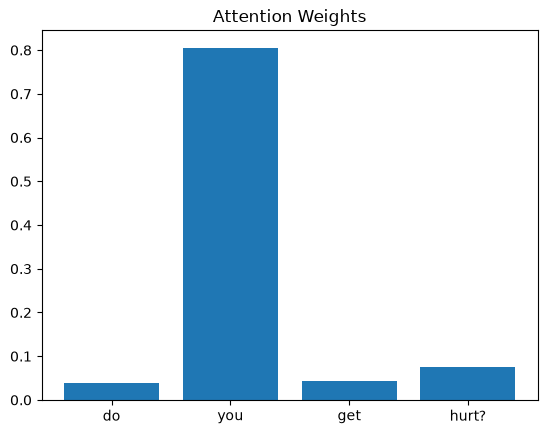

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question : do you get hurt?
Predicted answer: I don't have a body.
Highest attention: 'you' (0.84)
Weights : {'do': 0.04, 'you': 0.84, 'get': 0.04, 'hurt': 0.08} 

Question : how old are you?
Predicted answer: Age doesn't really apply to me.
Highest attention: 'how' (0.55)
Weights : {'how': 0.55, 'old': 0.28, 'are': 0.05, 'you': 0.13} 

Question : are you nonbinary?
Predicted answer: That's a biological concept that doesn't apply to me.
Highest attention: 'nonbinary' (1.00)
Weights : {'are': 0.0, 'you': 0.0, 'nonbinary': 1.0} 



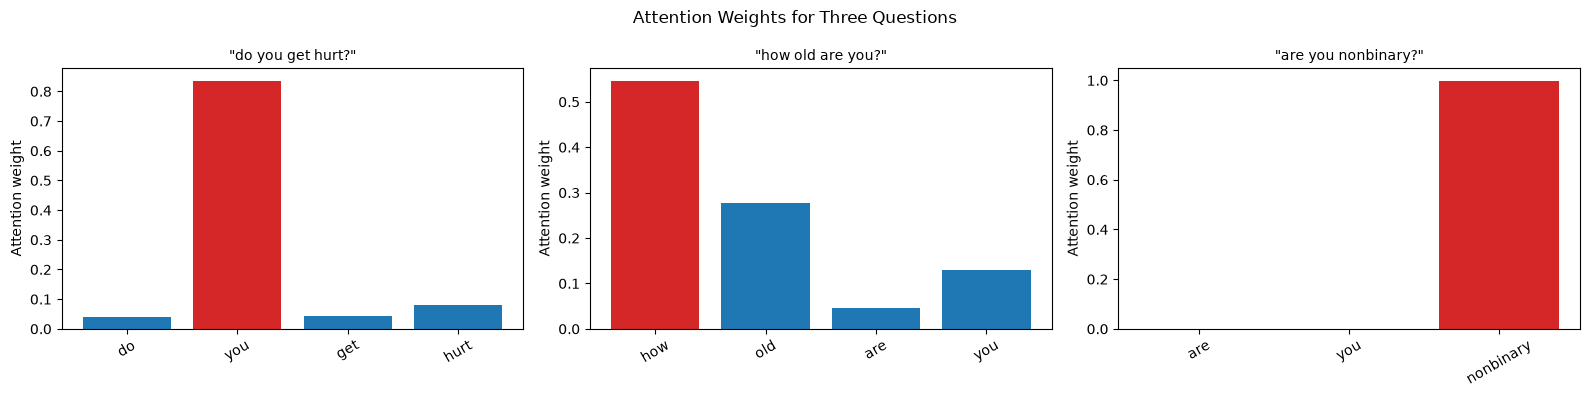

In [7]:
def attention_for(question):
    """Run one question through the model and return its words, attention weights and predicted answer."""
    seq = tokenizer.texts_to_sequences([question.lower()])[0]       # no padding -> only real words
    words = [tokenizer.index_word[i] for i in seq]
    with torch.no_grad():
        logits, weights = model(torch.tensor([seq], dtype=torch.long))
    answer_id = logits.argmax(1).item()
    answer = df.loc[df["answer_id"] == answer_id, "answer"].iloc[0]
    return words, weights[0].tolist(), answer

question_ids = [0, 24, 60]          # three different questions from three answer groups
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, idx in zip(axes, question_ids):
    question = df["question"][idx]
    words, weights, answer = attention_for(question)
    top = max(range(len(words)), key=lambda i: weights[i])

    colors = ["tab:red" if i == top else "tab:blue" for i in range(len(words))]
    ax.bar(words, weights, color=colors)
    ax.set_title(f'"{question}"', fontsize=10)
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=30)

    print(f"Question : {question}")
    print(f"Predicted answer: {answer}")
    print(f"Highest attention: '{words[top]}' ({weights[top]:.2f})")
    print("Weights :", {w: round(a, 2) for w, a in zip(words, weights)}, "\n")

plt.suptitle("Attention Weights for Three Questions")
plt.tight_layout()
plt.show()

**Observations**

| Question | Highest-attention word | Predicted answer |
|---|---|---|
| do you get hurt? | **you** (0.84) | I don't have a body. ✔ |
| how old are you? | **how** (0.55), then *old* (0.28) | Age doesn't really apply to me. ✔ |
| are you nonbinary? | **nonbinary** (1.00) | That's a biological concept that doesn't apply to me. ✔ |

**Do the highest-weighted words look important?** Partly.
- For *"are you nonbinary?"* the model puts almost all its attention on **nonbinary**, which is clearly the key word.
- For *"how old are you?"* most of the weight goes to **how + old** (0.83 together), which is the meaningful part of the question.
- For *"do you get hurt?"* the top word is **you**, which is not the most informative word (*hurt* gets only 0.08). The model still answers correctly because, in this small dataset, the RNN hidden state at the position of *you* already carries information from the start of the question (*do you ...* questions in this group are about the body).

So attention often points at meaningful words, but not always. The model learns whatever helps it **separate the answer groups in its training data**, which is not necessarily what a human would call "important". Note also that with a uni-directional RNN, each position's hidden state summarizes all the words before it, so a high weight on one word partly reflects its preceding context too.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question : How old are you?
Predicted answer: Age doesn't really apply to me.
Highest attention: 'how' (0.55)
Weights : {'how': 0.55, 'old': 0.28, 'are': 0.05, 'you': 0.13} 

Question : What's your age?
Predicted answer: Age doesn't really apply to me.
Highest attention: 'age' (0.65)
Weights : {"what's": 0.19, 'your': 0.16, 'age': 0.65} 



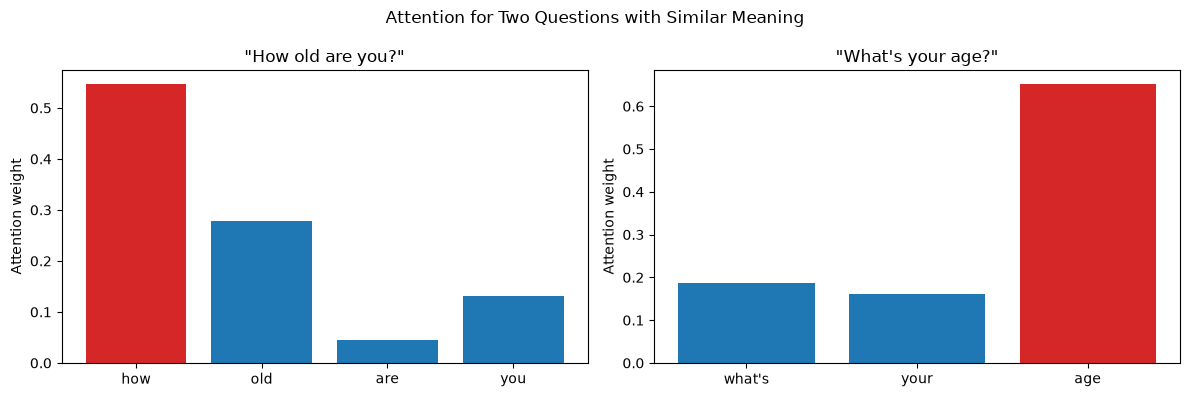

In [8]:
similar_questions = ["How old are you?", "What's your age?"]     # same meaning (answer group 1), different wording

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, question in zip(axes, similar_questions):
    words, weights, answer = attention_for(question)
    top = max(range(len(words)), key=lambda i: weights[i])

    ax.bar(words, weights, color=["tab:red" if i == top else "tab:blue" for i in range(len(words))])
    ax.set_title(f'"{question}"')
    ax.set_ylabel("Attention weight")

    print(f"Question : {question}")
    print(f"Predicted answer: {answer}")
    print(f"Highest attention: '{words[top]}' ({weights[top]:.2f})")
    print("Weights :", {w: round(a, 2) for w, a in zip(words, weights)}, "\n")

plt.suptitle("Attention for Two Questions with Similar Meaning")
plt.tight_layout()
plt.show()

**Comparison**

| Question | Highest-attention word | Predicted answer |
|---|---|---|
| How old are you? | **how** (0.55), *old* (0.28) | Age doesn't really apply to me. |
| What's your age? | **age** (0.65) | Age doesn't really apply to me. |

Both questions are mapped to the **same correct answer**, but the model focuses on **different words**. In each case it focuses on the words that carry the meaning in that particular wording: *how/old* in the first question and *age* in the second. Function words such as *are*, *you*, *your* receive low weights.

**What this suggests:** attention is **not a fixed list of important keywords**. It is computed dynamically for every input, and the model learns to pick out whichever words signal the intent in that specific phrasing. Different words (*old* vs *age*) lead to the same answer because the network learned during training that both belong to the same answer group. Attention therefore makes the model more **interpretable** and **robust to paraphrasing**.